<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Merged Dataset Shape: (763, 49)

Target Source: hpv_association_p16

Class Distribution:
HPV
0    191
1    141
Name: count, dtype: int64

Selected Input Columns:
age_at_initial_diagnosis: age_at_initial_diagnosis
sex: sex
smoking_status: smoking_status
primary_tumor_site: primary_tumor_site
primarily_metastasis: primarily_metastasis
pN_stage: pN_stage

Dataset Shape: (332, 6)
Number of Input Features: 6

Class Distribution:
HPV
0    191
1    141
Name: count, dtype: int64

Training Patients: 215
Validation Patients: 50
Test Patients: 67

Missing values handled using training-set statistics only.

Training samples without SMOTE:
HPV
0    123
1     92
Name: count, dtype: int64

Automatic Class Weights:
{0: 0.8739837398373984, 1: 1.1684782608695652}

Validation Threshold Selection
--------------------------------
Best Threshold: 0.69
Validation Balanced Accuracy: 0.6388

Classification Report

              precision    recall  f1-score   support

HPV Negative    

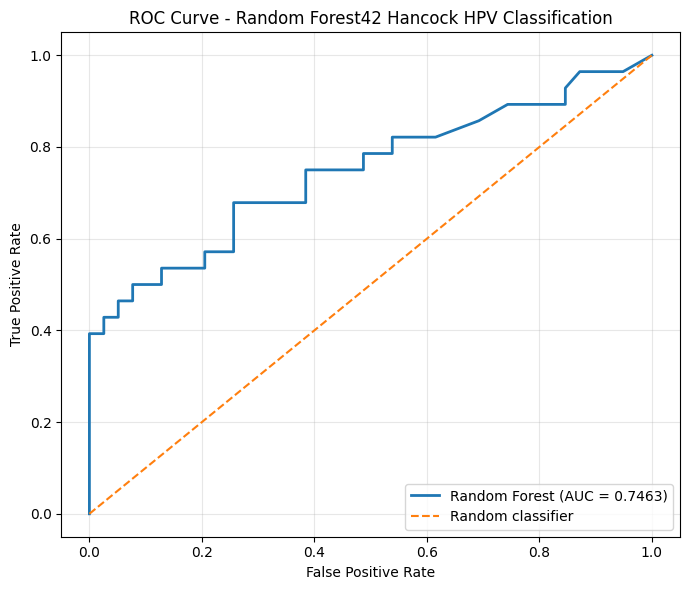

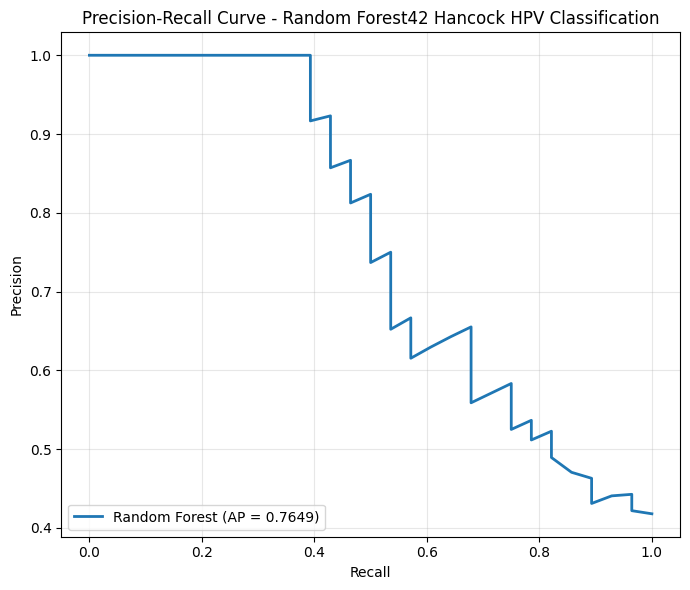


Feature Importance:
                 feature  importance
age_at_initial_diagnosis    0.459708
                pN_stage    0.358606
          smoking_status    0.119599
                     sex    0.044794
    primarily_metastasis    0.012275
      primary_tumor_site    0.005017


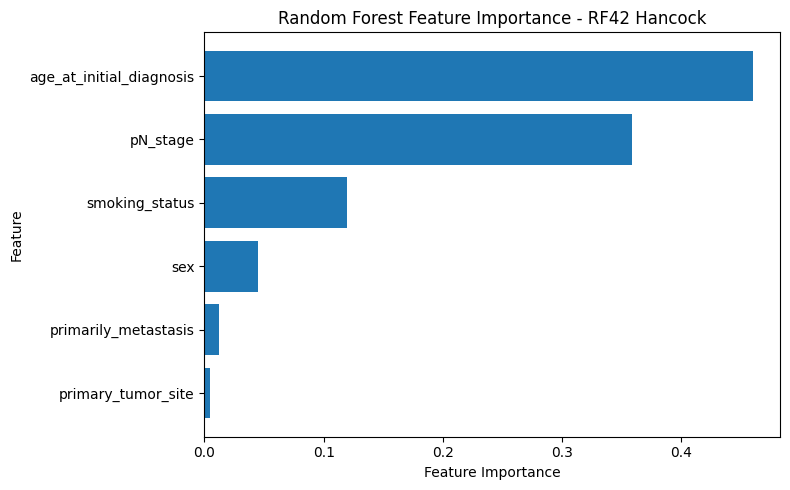


Saved Results To: /content/drive/MyDrive/RF_results

Analysis Complete.


In [1]:

# ============================================================
# RF42_HANCOCK
# Random Forest HPV Classification
# Consistent with LR42_HANCOCK preprocessing and evaluation
# 6 Input Features
# Train / Validation / Test Split
# No SMOTE
# Automatic Class Weights
# No Data Leakage
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

# ============================================================
# Imports
# ============================================================

import os
import json
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

# ============================================================
# Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# ============================================================
# Paths
# ============================================================

CLINICAL_PATH = '/content/drive/MyDrive/clinical_data.json'
PATHOLOGY_PATH = '/content/drive/MyDrive/pathological_data.json'

OUTPUT_DIR = '/content/drive/MyDrive/RF_results'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# Read Data
# ============================================================

with open(CLINICAL_PATH, 'r') as f:
    clinical = pd.DataFrame(json.load(f))

with open(PATHOLOGY_PATH, 'r') as f:
    pathology = pd.DataFrame(json.load(f))

# Left join and suffix overlapping columns consistently
df = clinical.merge(
    pathology,
    on='patient_id',
    how='left',
    suffixes=('', '_path')
)

print("Merged Dataset Shape:", df.shape)

# ============================================================
# HPV Labels
# ============================================================

# Prefer the clinical HPV label; use pathology label as fallback
if 'hpv_association_p16' in df.columns:
    target_source = 'hpv_association_p16'
elif 'hpv_association_p16_path' in df.columns:
    target_source = 'hpv_association_p16_path'
else:
    raise KeyError(
        "Neither hpv_association_p16 nor "
        "hpv_association_p16_path was found."
    )

# Use the same positive/negative target normalization
df[target_source] = (
    df[target_source]
    .astype('string')
    .str.strip()
    .str.lower()
)

df = df[
    df[target_source].isin(['positive', 'negative'])
].copy()

df['HPV'] = df[target_source].map({
    'negative': 0,
    'positive': 1
}).astype(int)

print("\nTarget Source:", target_source)
print("\nClass Distribution:")
print(df['HPV'].value_counts().sort_index())

# ============================================================
# Build Modelling Dataset
# Same 6 input features as CNN and ANN
# ============================================================

feature_candidates = {
    'age_at_initial_diagnosis': [
        'age_at_initial_diagnosis'
    ],
    'sex': [
        'sex'
    ],
    'smoking_status': [
        'smoking_status'
    ],
    'primary_tumor_site': [
        'primary_tumor_site'
    ],
    'primarily_metastasis': [
        'primarily_metastasis'
    ],
    'pN_stage': [
        'pN_stage',
        'pN_stage_path',
        'pathological_N_stage',
        'pathological_n_stage'
    ]
}

selected_features = {}

for feature, candidates in feature_candidates.items():
    selected = next(
        (col for col in candidates if col in df.columns),
        None
    )

    if selected is None:
        raise KeyError(
            f"Could not find a column for feature '{feature}'. "
            f"Checked: {candidates}"
        )

    selected_features[feature] = selected

print("\nSelected Input Columns:")
for feature, source_column in selected_features.items():
    print(f"{feature}: {source_column}")

df_model = pd.DataFrame(index=df.index)

for feature, source_column in selected_features.items():
    df_model[feature] = df[source_column]

df_model['HPV'] = df['HPV']

# ============================================================
# Features and Target
# ============================================================

X = df_model.drop(columns=['HPV']).copy()
y = df_model['HPV'].copy()

n_features = X.shape[1]

print("\nDataset Shape:", X.shape)
print("Number of Input Features:", n_features)

print("\nClass Distribution:")
print(y.value_counts().sort_index())

# ============================================================
# Train / Validation / Test Split
# Seed 42
# Stratified by HPV
#
# 20% test
# 15% validation
# 65% training
# ============================================================

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# 0.1875 of the remaining 80% gives 15% of the full dataset
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=y_train_val
)

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

y_train = y_train.copy()
y_val = y_val.copy()
y_test = y_test.copy()

print("\nTraining Patients:", len(y_train))
print("Validation Patients:", len(y_val))
print("Test Patients:", len(y_test))

# ============================================================
# Feature Types
# ============================================================

cat_cols = [
    'sex',
    'smoking_status',
    'primary_tumor_site',
    'primarily_metastasis',
    'pN_stage'
]

num_cols = [
    'age_at_initial_diagnosis'
]

# ============================================================
# Missing Values
# Statistics are learned from training data ONLY
# ============================================================

# Clean categorical missing-value representations
missing_strings = [
    '',
    'nan',
    'none',
    'null',
    'na',
    'n/a'
]

for col in cat_cols:
    for split_df in [X_train, X_val, X_test]:
        split_df[col] = split_df[col].apply(
            lambda value: (
                np.nan
                if pd.isna(value)
                or str(value).strip().lower() in missing_strings
                else str(value).strip()
            )
        )

for col in cat_cols:
    mode_values = X_train[col].mode(dropna=True)

    if len(mode_values) > 0:
        fill_value = mode_values.iloc[0]
    else:
        fill_value = 'Unknown'

    X_train[col] = X_train[col].fillna(fill_value)
    X_val[col] = X_val[col].fillna(fill_value)
    X_test[col] = X_test[col].fillna(fill_value)

for col in num_cols:
    X_train[col] = pd.to_numeric(
        X_train[col], errors='coerce'
    )
    X_val[col] = pd.to_numeric(
        X_val[col], errors='coerce'
    )
    X_test[col] = pd.to_numeric(
        X_test[col], errors='coerce'
    )

    median_value = X_train[col].median()

    if pd.isna(median_value):
        median_value = 0.0

    X_train[col] = X_train[col].fillna(median_value)
    X_val[col] = X_val[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

print("\nMissing values handled using training-set statistics only.")

# ============================================================
# Ordinal Encoding
# Fit encoder on training data ONLY
# ============================================================

encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train[cat_cols] = encoder.fit_transform(
    X_train[cat_cols].astype(str)
)

X_val[cat_cols] = encoder.transform(
    X_val[cat_cols].astype(str)
)

X_test[cat_cols] = encoder.transform(
    X_test[cat_cols].astype(str)
)

# ============================================================
# Standardisation
# Fit scaler on training data ONLY
# ============================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# ============================================================
# No SMOTE
# ============================================================

print("\nTraining samples without SMOTE:")
print(pd.Series(y_train).value_counts().sort_index())

# ============================================================
# Automatic Class Weights
# Calculated from training labels ONLY
# ============================================================

class_counts = np.bincount(
    y_train.to_numpy(),
    minlength=2
)

if np.any(class_counts == 0):
    raise ValueError(
        "Both classes must be present in the training set."
    )

class_weights = (
    len(y_train) /
    (len(class_counts) * class_counts)
)

class_weight_dict = {
    i: float(class_weights[i])
    for i in range(len(class_weights))
}

print("\nAutomatic Class Weights:")
print(class_weight_dict)

# ============================================================
# Random Forest Model
# Keep the original RF model configuration
# ============================================================

model = RandomForestClassifier(
    n_estimators=100,
    class_weight=class_weight_dict,
    random_state=SEED
)

model.fit(X_train, y_train)

# Save the fitted model and training-only preprocessing
joblib.dump(
    {
        'model': model,
        'encoder': encoder,
        'scaler': scaler,
        'categorical_columns': cat_cols,
        'numerical_columns': num_cols,
        'selected_features': selected_features,
        'target_source': target_source
    },
    os.path.join(OUTPUT_DIR, 'RF42_Hancock_model.joblib')
)

# ============================================================
# Validation Predictions
# Choose threshold using validation data ONLY
# ============================================================

val_probabilities = model.predict_proba(X_val)[:, 1]

val_thresholds = np.unique(
    np.concatenate([
        val_probabilities,
        np.array([0.5])
    ])
)

threshold_results = []

for threshold in val_thresholds:
    val_predicted = (
        val_probabilities >= threshold
    ).astype(int)

    val_bal_acc = balanced_accuracy_score(
        y_val,
        val_predicted
    )

    threshold_results.append({
        'threshold': float(threshold),
        'balanced_accuracy': float(val_bal_acc),
        'distance_from_0_5': abs(float(threshold) - 0.5)
    })

threshold_df = pd.DataFrame(threshold_results)

# Maximise validation balanced accuracy;
# break ties by choosing the threshold closest to 0.5
best_bal_acc = threshold_df['balanced_accuracy'].max()

best_candidates = threshold_df[
    threshold_df['balanced_accuracy'] == best_bal_acc
].copy()

best_candidates = best_candidates.sort_values(
    by=['distance_from_0_5', 'threshold'],
    ascending=[True, True]
)

best_threshold = float(
    best_candidates.iloc[0]['threshold']
)

print("\nValidation Threshold Selection")
print("--------------------------------")
print("Best Threshold:", best_threshold)
print(
    "Validation Balanced Accuracy:",
    f"{best_bal_acc:.4f}"
)

threshold_df.to_csv(
    os.path.join(OUTPUT_DIR, 'validation_threshold_results.csv'),
    index=False
)

# ============================================================
# Test Predictions
# Evaluate the held-out test set ONCE using the selected
# validation threshold
# ============================================================

test_probabilities = model.predict_proba(X_test)[:, 1]

predicted = (
    test_probabilities >= best_threshold
).astype(int)

# ============================================================
# Classification Report
# ============================================================

print("\nClassification Report\n")

print(
    classification_report(
        y_test,
        predicted,
        labels=[0, 1],
        target_names=['HPV Negative', 'HPV Positive'],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_test,
    predicted,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

# ============================================================
# Metrics
# ============================================================

accuracy = accuracy_score(y_test, predicted)

bal_acc = balanced_accuracy_score(
    y_test,
    predicted
)

f1 = f1_score(
    y_test,
    predicted,
    zero_division=0
)

precision = precision_score(
    y_test,
    predicted,
    zero_division=0
)

recall = recall_score(
    y_test,
    predicted,
    zero_division=0
)

auc = roc_auc_score(
    y_test,
    test_probabilities
)

pr_auc = average_precision_score(
    y_test,
    test_probabilities
)

print()
print(f"Accuracy:            {accuracy:.4f}")
print(f"Balanced Accuracy:   {bal_acc:.4f}")
print(f"F1-score:            {f1:.4f}")
print(f"Precision:           {precision:.4f}")
print(f"Recall:              {recall:.4f}")
print(f"ROC AUC:             {auc:.4f}")
print(f"PR AUC:              {pr_auc:.4f}")

# ============================================================
# Save Test Predictions
# ============================================================

predictions_df = pd.DataFrame({
    'y_true': y_test.to_numpy(),
    'y_pred': predicted,
    'probability_HPV_positive': test_probabilities,
    'threshold': best_threshold
})

predictions_df.to_csv(
    os.path.join(OUTPUT_DIR, 'test_predictions.csv'),
    index=False
)

# ============================================================
# Save Metrics
# ============================================================

metrics = {
    'model': 'Random Forest',
    'model_name': 'RF42_Hancock',
    'input_features': n_features,
    'feature_names': list(X.columns),
    'target_source': target_source,
    'accuracy': float(accuracy),
    'balanced_accuracy': float(bal_acc),
    'f1_score': float(f1),
    'precision': float(precision),
    'recall': float(recall),
    'roc_auc': float(auc),
    'pr_auc': float(pr_auc),
    'validation_threshold': float(best_threshold),
    'validation_balanced_accuracy': float(best_bal_acc),
    'n_estimators': 100,
    'class_weights': class_weight_dict,
    'smote': False,
    'seed': SEED,
    'training_patients': int(len(y_train)),
    'validation_patients': int(len(y_val)),
    'test_patients': int(len(y_test)),
    'train_test_validation_split': {
        'training': 0.65,
        'validation': 0.15,
        'test': 0.20
    }
}

with open(
    os.path.join(OUTPUT_DIR, 'metrics.json'),
    'w'
) as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame([metrics]).to_csv(
    os.path.join(OUTPUT_DIR, 'metrics.csv'),
    index=False
)

# ============================================================
# Model Summary
# ============================================================

print("\n====================================")
print("RANDOM FOREST42_HANCOCK SUMMARY")
print("====================================")
print("Model: Random Forest")
print("Input Features:", n_features)
print("Features:", list(X.columns))
print("Estimators:", 100)
print("Random State:", SEED)
print("Train / Validation / Test: 65 / 15 / 20")
print("Stratification: HPV")
print("SMOTE: No")
print("Class Weights: Automatic, training data only")
print("Imputation: Training-derived mode / median")
print("Encoding: Training-fitted OrdinalEncoder")
print("Scaling: Training-fitted StandardScaler")
print("Threshold: Selected on validation set")
print("Training Patients:", len(y_train))
print("Validation Patients:", len(y_val))
print("Test Patients:", len(y_test))

print("\nFinal Test Results")
print("---------------------------")
print(f"Accuracy            : {accuracy:.4f}")
print(f"Balanced Accuracy   : {bal_acc:.4f}")
print(f"F1-score            : {f1:.4f}")
print(f"Precision           : {precision:.4f}")
print(f"Recall              : {recall:.4f}")
print(f"ROC AUC             : {auc:.4f}")
print(f"PR AUC              : {pr_auc:.4f}")
print(f"Selected Threshold  : {best_threshold:.4f}")

print("\nConfusion Matrix")
print(cm)

# ============================================================
# ROC / AUC Curve
# ============================================================

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f'Random Forest (AUC = {auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest42 Hancock HPV Classification')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, 'roc_curve.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# Precision-Recall Curve
# ============================================================

precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(
        y_test,
        test_probabilities
    )
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    linewidth=2,
    label=f'Random Forest (AP = {pr_auc:.4f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(
    'Precision-Recall Curve - Random Forest42 Hancock HPV Classification'
)
plt.legend(loc='lower left')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, 'precision_recall_curve.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# Feature Importance
# ============================================================

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': model.feature_importances_
}).sort_values(
    by='importance',
    ascending=False
)

feature_importance.to_csv(
    os.path.join(OUTPUT_DIR, 'feature_importance.csv'),
    index=False
)

print("\nFeature Importance:")
print(feature_importance.to_string(index=False))

plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance['feature'][::-1],
    feature_importance['importance'][::-1]
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance - RF42 Hancock')
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, 'feature_importance.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# Save Settings
# ============================================================

settings = {
    'model': 'RandomForestClassifier',
    'n_estimators': 100,
    'random_state': SEED,
    'features': list(X.columns),
    'selected_source_columns': selected_features,
    'target_source': target_source,
    'target_mapping': {
        'negative': 0,
        'positive': 1
    },
    'split': {
        'training': 0.65,
        'validation': 0.15,
        'test': 0.20,
        'stratified': True,
        'random_state': SEED
    },
    'smote': False,
    'class_weight': class_weight_dict,
    'threshold_selection': (
        'Maximum validation balanced accuracy; '
        'ties resolved by closest threshold to 0.5'
    ),
    'preprocessing': {
        'imputation': 'Training-derived mode and median',
        'encoding': 'OrdinalEncoder fitted on training set',
        'scaling': 'StandardScaler fitted on training set'
    }
}

with open(
    os.path.join(OUTPUT_DIR, 'settings.json'),
    'w'
) as f:
    json.dump(settings, f, indent=4)

print("\nSaved Results To:", OUTPUT_DIR)
print("\nAnalysis Complete.")
